# Tema 4. Extracción de características (_Hand Engineered Features_)

Visión Artificial · Máster en Inteligencia Artificial · Universidad de Murcia · 2026/2027

Seguimos el recorrido de teoría: bordes y gradientes, Canny, puntos de interés, Harris, Hessiano, FAST y SIFT, hasta el _matching_ y el reconocimiento de un objeto planar. Al final, el ejemplo adicional de HOG sirve de puente entre descriptores locales y un descriptor de la imagen completa.

Un **detector** decide dónde hay una característica; un **descriptor** representa su entorno para compararlo con otros. Buscamos repetibilidad, localización precisa, capacidad discriminante y robustez frente a cambios de escala, orientación e iluminación, con un coste razonable. La invarianza es aproximada: textura repetida, grandes cambios de vista y oclusiones pueden producir correspondencias ambiguas o eliminar características.

## Entorno e imports

Este notebook funciona en CPU, tanto en Jupyter local como en Colab. En local usamos
Python 3.11 y `requirements-base.txt` (véanse `README.md` e `INSTALL.md`). Necesitamos
NumPy, SciPy, Matplotlib, scikit-image y OpenCV; SIFT está incluido en OpenCV estándar.
Las imágenes del libro se descargan una sola vez y se guardan en `output/06_features/`.
Las imágenes de scikit-image también pueden requerir una descarga inicial a su caché.

In [1]:
import sys
from pathlib import Path
from urllib.request import urlopen
import math
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import skimage
import skimage.transform as transform
import skimage.feature as feature
import skimage.draw as draw
import skimage.color as color
import skimage.filters as filters
from skimage.feature import blob_dog, blob_log, blob_doh, hog
from skimage import data, exposure
from scipy import ndimage as ndi
from matplotlib import colors as mcolors

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
print("Entorno:", "Google Colab" if IN_COLAB else "Jupyter local")
print("Python:", sys.version.split()[0], "OpenCV:", cv2.__version__, "scikit-image:", skimage.__version__)

Entorno: Jupyter local
Python: 3.11.11 OpenCV: 4.14.0 scikit-image: 0.26.0


### Imágenes de prueba

In [2]:
img_checkerboard = skimage.data.checkerboard()
imgs_motorcycle = skimage.data.stereo_motorcycle()[:2]
img_camera = skimage.data.camera()
img_hubble_gray = color.rgb2gray(data.hubble_deep_field()[0:500, 0:500])

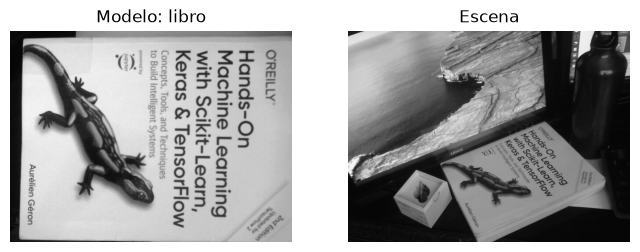

In [3]:
# Funciona tanto al abrir el fuente como al ejecutar su copia dentro de output/.
output_root = Path.cwd() if Path.cwd().name == "output" else Path.cwd() / "output"
data_dir = output_root / "06_features"
data_dir.mkdir(parents=True, exist_ok=True)

def download_image(url, filename):
    path = data_dir / filename
    if not path.exists() or path.stat().st_size == 0:
        with urlopen(url, timeout=30) as response:
            payload = response.read()
        if cv2.imdecode(np.frombuffer(payload, dtype=np.uint8), cv2.IMREAD_GRAYSCALE) is None:
            raise ValueError(f"La descarga no contiene una imagen válida: {url}")
        path.write_bytes(payload)
    return path

def read_gray(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"No se puede leer la imagen: {path}")
    return image

model_path = download_image("https://ditec.um.es/~pedroe/HOML-model.jpg", "HOML-model.jpg")
scene_path = download_image("https://ditec.um.es/~pedroe/HOML-scene.jpg", "HOML-scene.jpg")
img1, img2 = read_gray(model_path), read_gray(scene_path)

def show_images(images, titles, cmap="gray", symmetric=False):
    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4), squeeze=False)
    limit = max(np.max(np.abs(image)) for image in images) if symmetric else None
    for ax, image, title in zip(axes.ravel(), images, titles):
        ax.imshow(image, cmap=cmap, vmin=-limit if symmetric else None, vmax=limit)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

show_images([img1, img2], ["Modelo: libro", "Escena"])

## 1. Bordes y estimación del gradiente

Un borde corresponde a un cambio local de intensidad. Primero calculamos derivadas con signo
en coma flotante, y después módulo y orientación. `atan2(Gy, Gx)` conserva el cuadrante;
en zonas con gradiente casi nulo la orientación no es significativa.
Roberts, Prewitt y Sobel utilizan distintos entornos y suavizados. Sus magnitudes no tienen
necesariamente la misma normalización: comparamos la estructura de las respuestas.

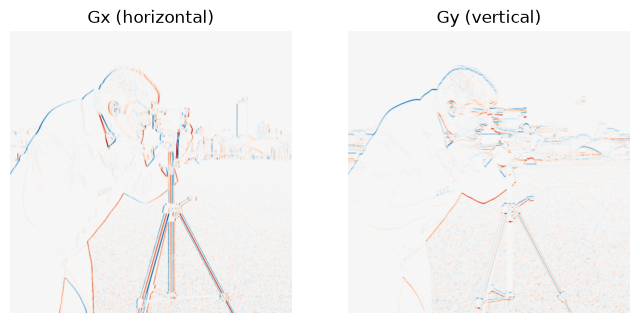

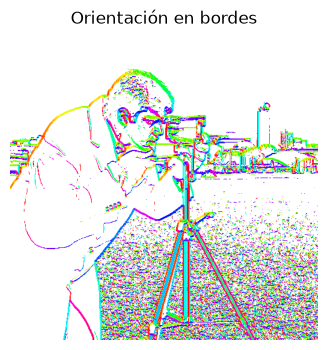

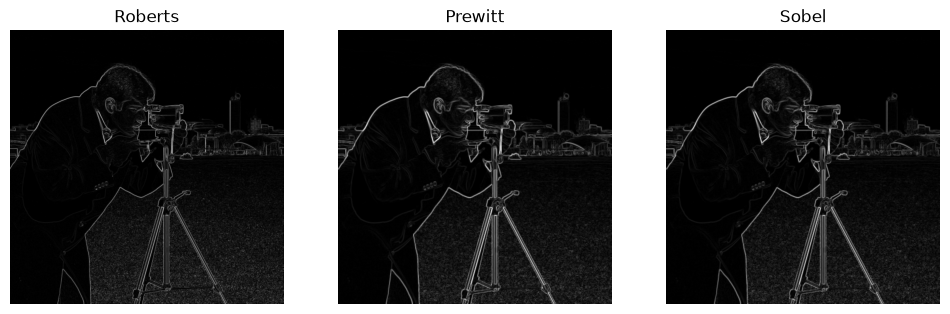

In [4]:
camera_float = skimage.img_as_float(img_camera)
gx = ndi.sobel(camera_float, axis=1) / 8
gy = ndi.sobel(camera_float, axis=0) / 8
magnitude = np.hypot(gx, gy)
orientation = np.arctan2(gy, gx)
show_images([gx, gy], ["Gx (horizontal)", "Gy (vertical)"], cmap="RdBu_r", symmetric=True)
show_images([np.where(magnitude > 0.03, orientation, np.nan)],
            ["Orientación en bordes"], cmap="hsv")
show_images([filters.roberts(camera_float), filters.prewitt(camera_float), filters.sobel(camera_float)],
            ["Roberts", "Prewitt", "Sobel"])

### Ruido, suavizado y escala

Derivar amplifica el ruido. Suavizar antes reduce falsas respuestas, pero ensancha los bordes
y puede borrar detalles. Las derivadas de una gaussiana combinan ambas operaciones.
En la gráfica 1D, observa el compromiso entre ruido y localización; después compara las escalas
en una imagen real. Para comparar respuestas a distintas escalas multiplicamos la derivada por σ.

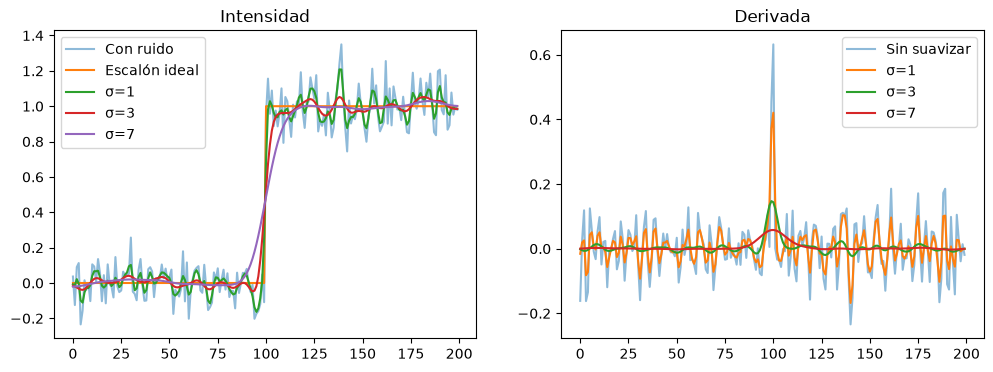

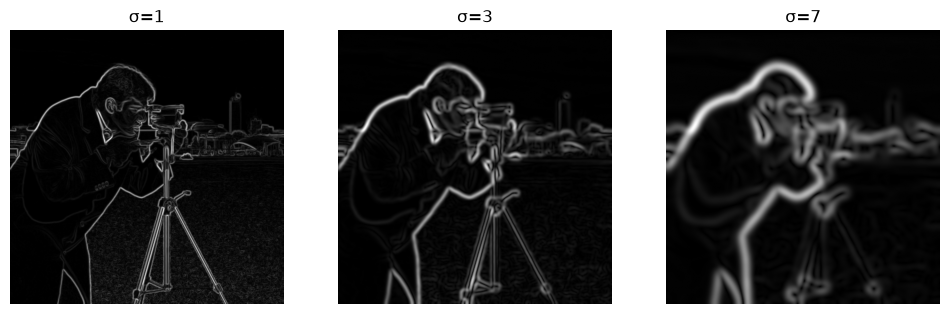

In [5]:
x = np.arange(200)
step = (x >= 100).astype(float)
noisy_step = step + rng.normal(0, 0.12, step.shape)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, noisy_step, label="Con ruido", alpha=0.5)
axes[0].plot(x, step, label="Escalón ideal")
axes[1].plot(x, np.gradient(noisy_step), label="Sin suavizar", alpha=0.5)
for sigma in (1, 3, 7):
    axes[0].plot(x, ndi.gaussian_filter1d(noisy_step, sigma), label=f"σ={sigma}")
    axes[1].plot(x, ndi.gaussian_filter1d(noisy_step, sigma, order=1), label=f"σ={sigma}")
for ax in axes:
    ax.legend()
axes[0].set_title("Intensidad")
axes[1].set_title("Derivada")
plt.show()

scaled_gradients = []
for sigma in (1, 3, 7):
    dx = ndi.gaussian_filter(camera_float, sigma, order=(0, 1))
    dy = ndi.gaussian_filter(camera_float, sigma, order=(1, 0))
    scaled_gradients.append(sigma * np.hypot(dx, dy))
show_images(scaled_gradients, ["σ=1", "σ=3", "σ=7"])

## 2. Canny: gradiente, supresión de no máximos e histéresis

En este ejemplo de uso del operador de Canny, `use_quantiles=True` hace que los umbrales sean **cuantiles** de la magnitud del gradiente, no intensidades absolutas.

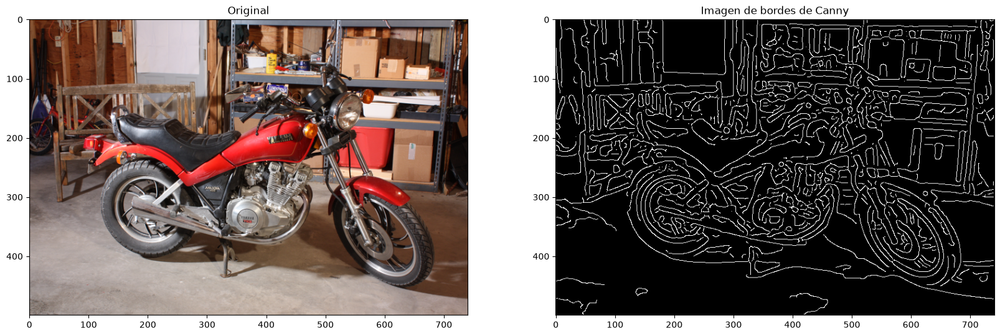

In [6]:
fig, axs = plt.subplots(1,2, figsize=(20,10))
axs[0].imshow(imgs_motorcycle[0])
axs[0].set_title("Original")
axs[1].imshow(feature.canny(color.rgb2gray(imgs_motorcycle[0]), sigma=3, low_threshold=0.1, high_threshold=0.5, use_quantiles=True), cmap="gray")
axs[1].set_title("Imagen de bordes de Canny");

### De bordes gruesos a bordes delgados

Este pequeño ejemplo ilustra las etapas, sin reproducir todos los detalles de la implementación
de Canny. Interpolamos el módulo un píxel hacia delante y hacia atrás en la dirección del
gradiente y conservamos máximos. La histéresis conecta respuestas débiles con fuertes mediante
conectividad de 8 vecinos; una respuesta débil aislada se elimina.

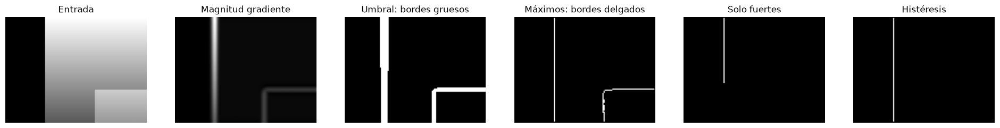

In [7]:
yy, xx = np.mgrid[:96, :128]
edge_example = (xx > 35).astype(float) * (1.0 - 0.65 * yy / 95)
edge_example += 0.25 * ((xx > 80) & (yy > 65))
dx = ndi.gaussian_filter(edge_example, 2, order=(0, 1))
dy = ndi.gaussian_filter(edge_example, 2, order=(1, 0))
mag = np.hypot(dx, dy)
angle = np.arctan2(dy, dx)
forward = ndi.map_coordinates(mag, [yy + np.sin(angle), xx + np.cos(angle)], order=1)
backward = ndi.map_coordinates(mag, [yy - np.sin(angle), xx - np.cos(angle)], order=1)
thin = np.where((mag >= forward) & (mag >= backward), mag, 0)
thin[[0, -1], :] = 0 # Eliminamos comparaciones en bordes
thin[:, [0, -1]] = 0 # 
low, high = 0.15 * mag.max(), 0.6 * mag.max()
strong, eligible = thin >= high, thin >= low
linked = ndi.binary_propagation(strong, structure=np.ones((3, 3)), mask=eligible)
show_images([edge_example, mag, mag > low, thin > low, strong, linked],
            ["Entrada", "Magnitud gradiente", "Umbral: bordes gruesos", "Máximos: bordes delgados", "Solo fuertes", "Histéresis"])

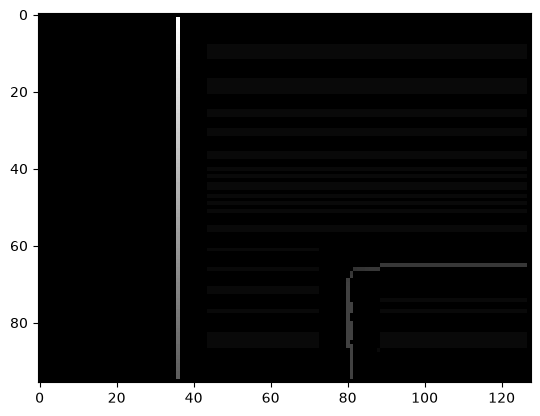

In [8]:
plt.imshow(thin, cmap="gray")

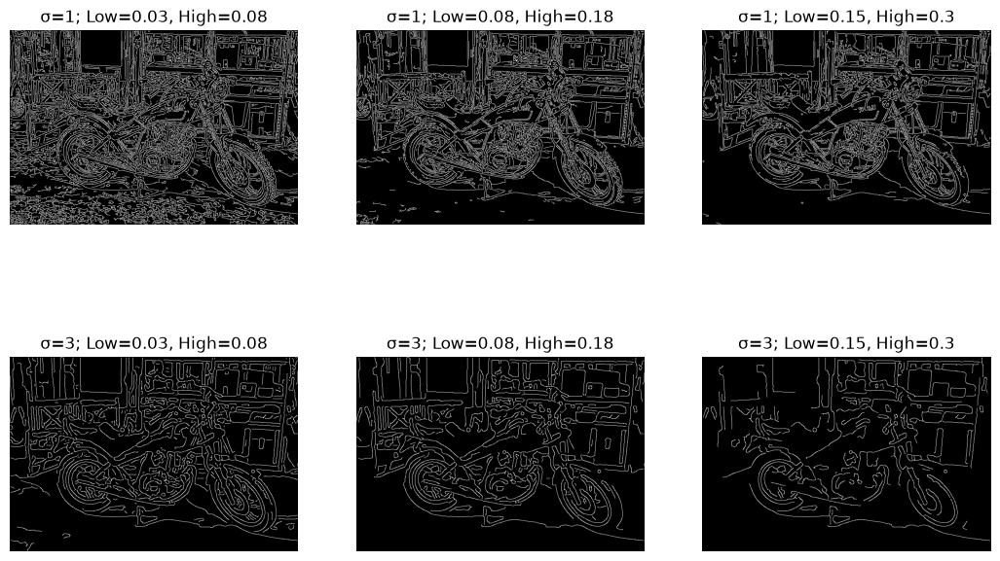

In [9]:
motorcycle_gray = color.rgb2gray(imgs_motorcycle[0])
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for row, sigma in enumerate((1, 3)):
    for col, (low, high) in enumerate(((0.03, 0.08), (0.08, 0.18), (0.15, 0.3))):
        edges = feature.canny(motorcycle_gray, sigma=sigma,
                              low_threshold=low, high_threshold=high, use_quantiles=False)
        axes[row, col].imshow(edges, cmap="gray")
        axes[row, col].set_title(f"σ={sigma}; Low={low}, High={high}")
        axes[row, col].axis("off")
plt.show()

**Prueba:** identifica un detalle que desaparece al aumentar σ. Mantén σ fijo y cambia
solo uno de los umbrales: ¿qué cambia en el enlace y en las falsas detecciones?

## 3. Estructura local: zona plana, borde y esquina

La matriz de estructura acumula productos de primeras derivadas en un entorno:

$$A=G_\sigma * \begin{pmatrix}I_x^2&I_xI_y\\I_xI_y&I_y^2\end{pmatrix}.$$

Dos autovalores pequeños indican poca textura; uno grande y otro pequeño indican un borde;
dos grandes indican una esquina. En estos parches sintéticos inspeccionamos el centro.

He aquí un ejemplo de detección de puntos cuya estructura fotométrica alrededor tiene textura suficiente para poder hacer viable un _matching_ sin la ambigüedad inherente a las zonas planas de imagen o a los bordes rectos (problema de apertura). Se trata del operador de Harris:

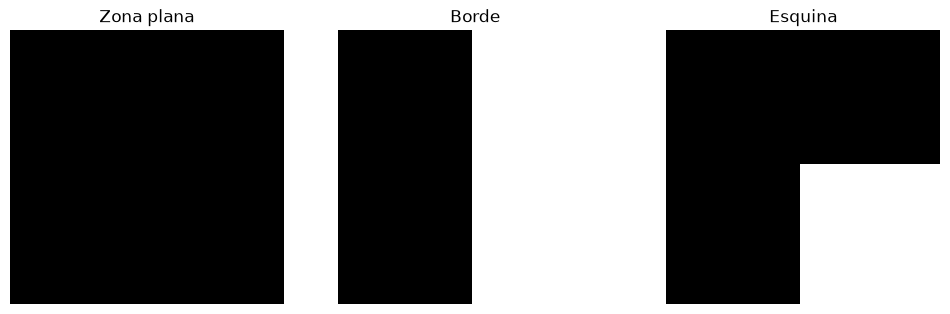

Plana autovalores: [0. 0.]
Borde autovalores: [0.         6.00816651]
Esquina autovalores: [2.54530349 3.74487915]


In [10]:
yy, xx = np.mgrid[:41, :41]
patches = [np.full((41, 41), 0.5), (xx >= 20).astype(float),
           ((xx >= 20) & (yy >= 20)).astype(float)]
show_images(patches, ["Zona plana", "Borde", "Esquina"])
for name, patch in zip(("Plana", "Borde", "Esquina"), patches):
    arr, arc, acc = feature.structure_tensor(patch, sigma=2, order="rc")
    matrix = np.array([[arr[20, 20], arc[20, 20]], [arc[20, 20], acc[20, 20]]])
    print(name, "autovalores:", np.linalg.eigvalsh(matrix))

### Respuesta de Harris, umbral y máximos locales

Harris resume la estructura mediante $R=\det(A)-k\,\mathrm{tr}(A)^2$.
Una respuesta positiva grande sugiere una esquina; los bordes suelen dar respuesta negativa.
Umbralizar deja grupos de píxeles; la supresión de no máximos selecciona localizaciones.

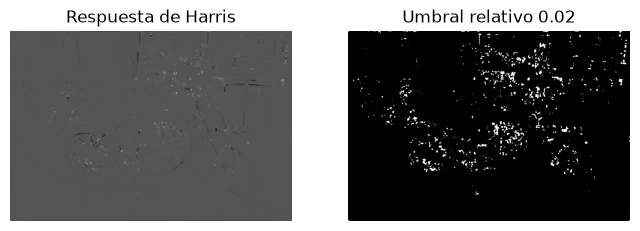

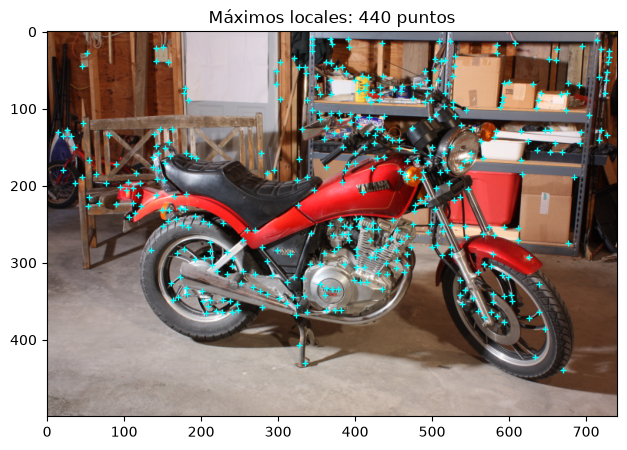

In [11]:
harris_response = feature.corner_harris(motorcycle_gray, method="k", k=0.05, sigma=1)
harris_mask = harris_response > 0.02 * harris_response.max()
harris_coords = feature.corner_peaks(harris_response, min_distance=5, threshold_rel=0.02)
show_images([harris_response, harris_mask], ["Respuesta de Harris", "Umbral relativo 0.02"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(imgs_motorcycle[0])
ax.plot(harris_coords[:, 1], harris_coords[:, 0], "+", color="cyan", markersize=5)
ax.set_title(f"Máximos locales: {len(harris_coords)} puntos")
plt.show()

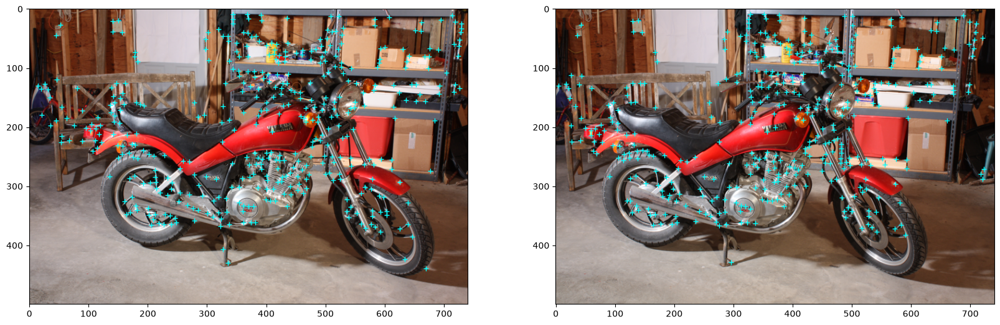

In [12]:
fig, axs = plt.subplots(1,2, figsize=(20,10))
for i,img in enumerate(imgs_motorcycle):
    coords = feature.corner_peaks(feature.corner_harris(color.rgb2gray(img)), min_distance=5, threshold_rel=0.02)
    axs[i].imshow(img, cmap=plt.cm.gray)
    axs[i].plot(coords[:, 1], coords[:, 0], color='cyan', marker='+', linestyle='None', markersize=6)
plt.show()

### Supresión de no máximos adaptativa (ANMS)

La selección por respuesta puede concentrar puntos en unas pocas zonas. ANMS prioriza puntos con gran distancia al punto de respuesta suficientemente mayor más cercano. Aquí usamos `R_i < 0.9 R_j` y limitamos a 500 candidatos para que el ejemplo cuadrático sea pequeño. Comparamos el mismo número de puntos; esto no garantiza una distribución uniforme perfecta, pero al menos sí que intenta evitar la aglomeración de muchas esquinas en zonas demasiado concentradas de la imagen.

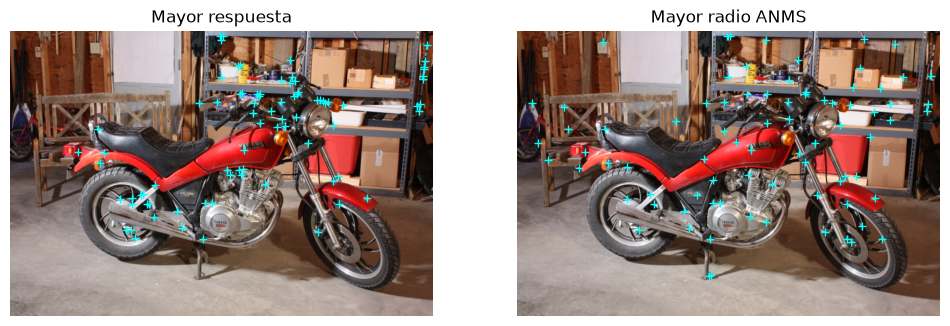

In [13]:
candidates = feature.corner_peaks(harris_response, min_distance=2, threshold_rel=0.02)
responses = harris_response[candidates[:, 0], candidates[:, 1]]
order = np.argsort(-responses, kind="stable")[:500]
candidates, responses = candidates[order], responses[order]
radii = np.full(len(candidates), np.inf)
for i, point in enumerate(candidates):
    stronger = responses > responses[i] / 0.9
    if stronger.any():
        radii[i] = np.linalg.norm(candidates[stronger] - point, axis=1).min()
count = min(80, len(candidates))
selected = np.argsort(-radii, kind="stable")[:count]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, coords, label in zip(axes, (candidates[:count], candidates[selected]),
                              ("Mayor respuesta", "Mayor radio ANMS")):
    ax.imshow(imgs_motorcycle[0])
    ax.plot(coords[:, 1], coords[:, 0], "+", color="cyan")
    ax.set_title(label)
    ax.axis("off")
plt.show()

### Ampliación: refinamiento subpíxel

El siguiente código crea una imagen de prueba con un tablero deformado mediante una transformación afín, una elipse y dos cuadrados. Después, detecta esquinas con el método de Harris y selecciona máximos suficientemente separados, _refinando sus posiciones con [precisión subpíxel](https://docs.opencv.org/4.12.0/dd/d1a/group__imgproc__feature.html#ga354e0d7c86d0d9da75de9b9701a9a87e) usando una ventana de 13×13 píxeles_ (y descartando los refinamientos no válidos):

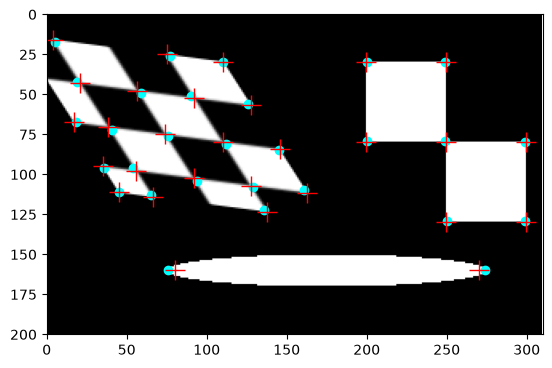

In [14]:
# Sheared checkerboard
tform = transform.AffineTransform(scale=(1.3, 1.1), rotation=1, shear=0.7,
                        translation=(110, 30))
image = transform.warp(img_checkerboard[:90, :90], tform.inverse,
             output_shape=(200, 310))
# Ellipse
rr, cc = draw.ellipse(160, 175, 10, 100)
image[rr, cc] = 1
# Two squares
image[30:80, 200:250] = 1
image[80:130, 250:300] = 1

coords = feature.corner_peaks(feature.corner_harris(image), min_distance=5, threshold_rel=0.02)
coords_subpix = feature.corner_subpix(image, coords, window_size=13)

fig, ax = plt.subplots()
ax.imshow(image, cmap=plt.cm.gray)
ax.plot(coords[:, 1], coords[:, 0], color='cyan', marker='o',
        linestyle='None', markersize=6)
valid_subpix = coords_subpix[np.isfinite(coords_subpix).all(axis=1)]
ax.plot(valid_subpix[:, 1], valid_subpix[:, 0], '+r', markersize=15)
ax.axis((0, 310, 200, 0))
plt.show()

## 4. Hessiano local y detección de blobs

El Hessiano utiliza **segundas derivadas**, en lugar de productos de gradientes, como la matriz de estructura: $H=\begin{pmatrix}I_{xx}&I_{xy}\\I_{xy}&I_{yy}\end{pmatrix}$.
Describe curvatura de la imagen (vista como función): dos autovalores negativos indican un máximo local (blob claro), dos positivos un mínimo (blob oscuro), uno casi nulo una cresta y signos opuestos una silla. La selección concreta depende del detector: el detector de blobs DoH no busca todos los puntos de silla.

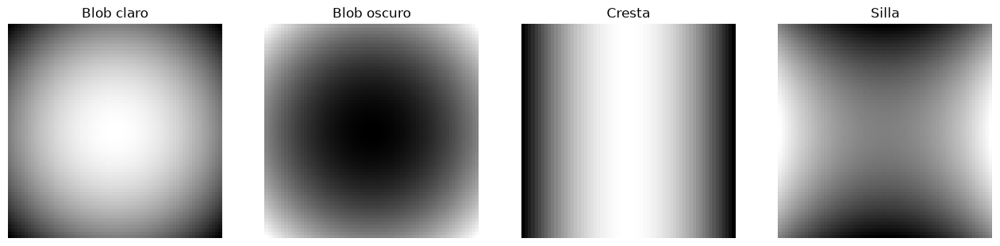

Claro autovalores: [-0.00195312 -0.00195312]
Oscuro autovalores: [0.00195312 0.00195312]
Cresta autovalores: [-0.00195312 -0.        ]
Silla autovalores: [-0.00195312  0.00195312]


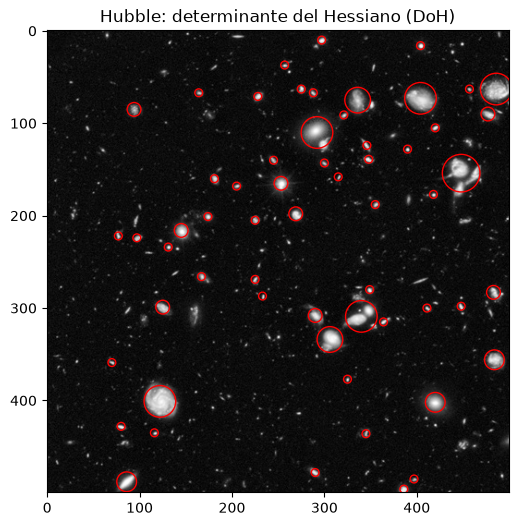

In [15]:
axis = np.linspace(-1, 1, 65)
xx, yy = np.meshgrid(axis, axis)
surfaces = [-xx**2 - yy**2, xx**2 + yy**2, -xx**2, xx**2 - yy**2]
show_images(surfaces, ["Blob claro", "Blob oscuro", "Cresta", "Silla"])
for name, surface in zip(("Claro", "Oscuro", "Cresta", "Silla"), surfaces):
    hrr, hrc, hcc = feature.hessian_matrix(surface, sigma=2, order="rc",
                                          use_gaussian_derivatives=True)
    hessian = np.array([[hrr[32, 32], hrc[32, 32]], [hrc[32, 32], hcc[32, 32]]])
    print(name, "autovalores:", np.linalg.eigvalsh(hessian))

blobs_doh = blob_doh(img_hubble_gray, max_sigma=30, threshold=0.01)
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img_hubble_gray, cmap="gray")
for row, col, sigma in blobs_doh:
    ax.add_patch(plt.Circle((col, row), sigma, color="red", linewidth=1, fill=False))
ax.set_title("Hubble: determinante del Hessiano (DoH)")
plt.show()

SURF aproxima derivadas mediante filtros rectangulares e imágenes integrales. El ejemplo DoH
ilustra esta familia de detectores multiescala; no es una implementación completa de SURF.
Volveremos a comparar estos blobs con LoG y DoG al entrar en SIFT.

## 5. FAST

FAST compara el centro con un círculo de 16 píxeles de radio 3. En esta demostración usamos
la variante **FAST-12**: exige 12 píxeles consecutivos más claros o más oscuros que el centro
por al menos el umbral indicado. FAST detecta puntos, pero no calcula un descriptor ni
selecciona una escala característica. Comparamos umbrales y activación de no máximos.

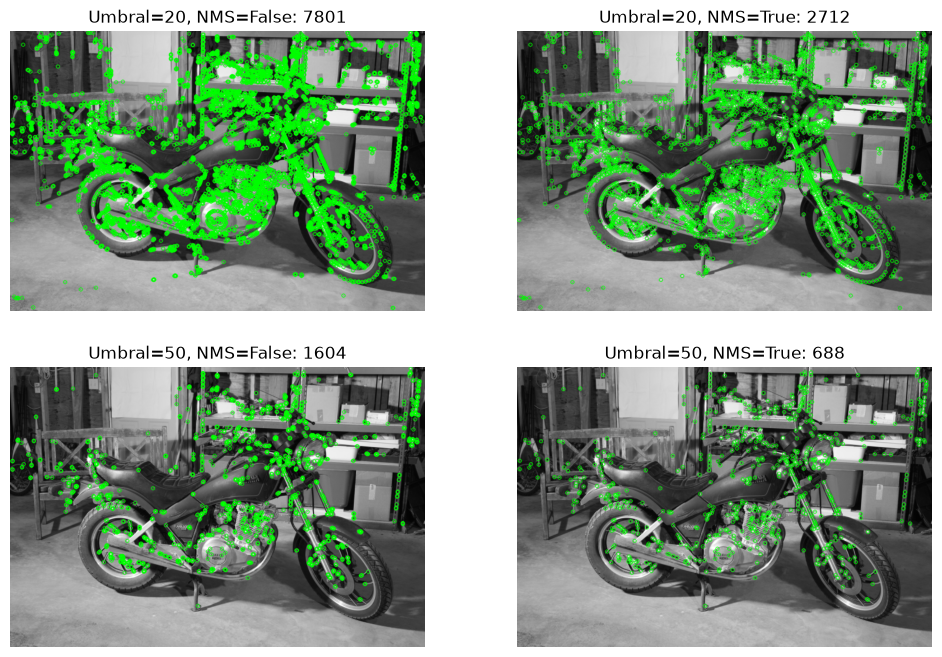

In [16]:
motorcycle_u8 = skimage.img_as_ubyte(motorcycle_gray)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, threshold in enumerate((20, 50)):
    for col, nonmax in enumerate((False, True)):
        fast_response = feature.corner_fast(motorcycle_gray, n=12, threshold=threshold / 255)
        coords = (feature.corner_peaks(fast_response, min_distance=1, threshold_rel=0)
                  if nonmax else np.argwhere(fast_response > 0))
        fast_points = [cv2.KeyPoint(float(col), float(row), 6) for row, col in coords]
        rendered = cv2.drawKeypoints(motorcycle_u8, fast_points, None, color=(0, 255, 0))
        axes[row, col].imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f"Umbral={threshold}, NMS={nonmax}: {len(fast_points)}")
        axes[row, col].axis("off")
plt.show()

## 6. SIFT: escala, localización, orientación y descriptor

SIFT combina un detector multiescala con un descriptor local. Buscamos características
repetibles frente a cambios de escala y orientación, y descriptores robustos a cambios
moderados de iluminación. Usaremos el ejemplo del libro para localizar un objeto planar
en una escena con fondo desconocido, separando correspondencias tentativas y verificación geométrica.

### Comparación de blobs: LoG, DoG y DoH

Se ilustran tres posibles métodos para computar _blobs_ en una imagen:
* Laplaciana de la Gaussiana
* Diferencia de Gaussianas (aproximación del anterior)
* Determinante del Hessiano (cuya aproximación integral es usada por SURF)

Ilustramos los resultados con una imagen obtenida con el telescopio Hubble, donde se aprecia bien la sensibilidad a los _blobs_ (en este caso galaxias) a distintas escalas:

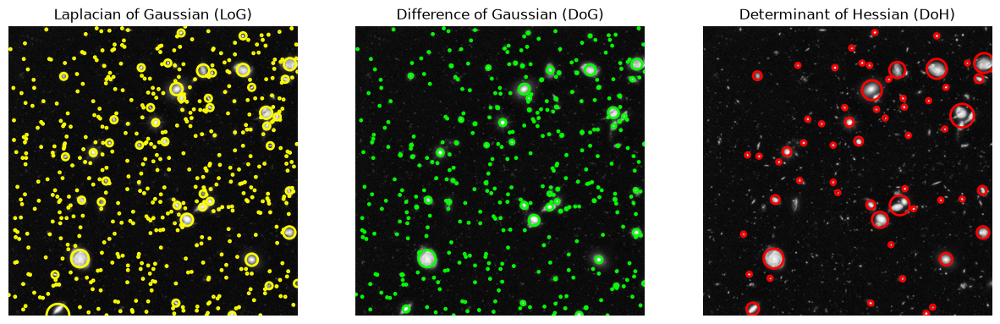

In [17]:
blobs_log = blob_log(img_hubble_gray, max_sigma=30, num_sigma=10, threshold=.1)
blobs_dog = blob_dog(img_hubble_gray, max_sigma=30, threshold=.1)
blobs_doh = blob_doh(img_hubble_gray, max_sigma=30, threshold=.01)

# Radio aproximado de LoG/DoG en 2D: sqrt(2) * sigma; no modificamos los resultados originales:
blobs_log = blobs_log.copy()
blobs_log[:, 2] *= math.sqrt(2)
blobs_dog = blobs_dog.copy()
blobs_dog[:, 2] *= math.sqrt(2)

blobs_list = [blobs_log, blobs_dog, blobs_doh]
colors = ['yellow', 'lime', 'red']
titles = ['Laplacian of Gaussian (LoG)', 'Difference of Gaussian (DoG)',
          'Determinant of Hessian (DoH)']

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for i, (blobs, plot_color, title) in enumerate(zip(blobs_list, colors, titles)):
    ax[i].set_title(title)
    ax[i].imshow(img_hubble_gray, cmap="gray")
    for blob in blobs:
        y, x, r = blob
        ax[i].add_patch(plt.Circle((x, y), r, color=plot_color, linewidth=2, fill=False))
    ax[i].set_axis_off()

### Paso 1. Extremos en el espacio de escala

LoG normalizada usa $\sigma^2\nabla^2(G_\sigma*I)$; DoG aproxima esta respuesta al restar simplemente dos gaussianas de escalas próximas (que es una aproximación bastatne buena). Buscamos **máximos y mínimos** en posición y escala. Este experimento usa una sola octava y tres blobs sintéticos de distinto tamaño; ilustra el principio, no sustituye el detector completo de SIFT. En Hubble, `blob_log` y `blob_dog` buscan blobs claros sobre fondo oscuro; SIFT considera ambos signos.

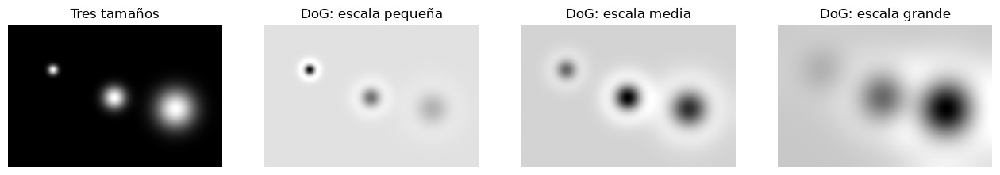

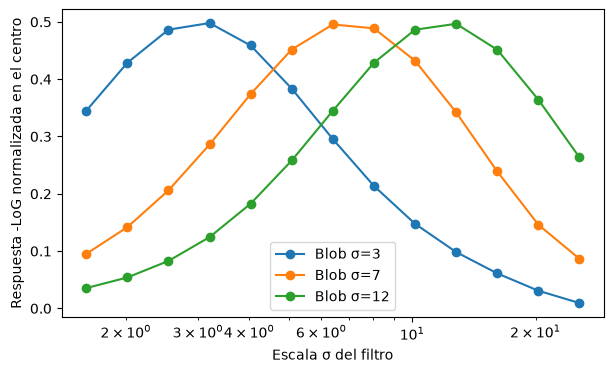

Extremos (nivel, fila, columna): [[  2  40  40]
 [  6  65  95]
 [  7  68 119]
 [  8  59 121]
 [  8  75 150]
 [  8  80 117]
 [  9  49 123]
 [  9  90 115]]


In [18]:
yy, xx = np.mgrid[:128, :192]
scale_image = np.zeros_like(xx, dtype=float)
blob_centers = [(40, 40, 3), (65, 95, 7), (75, 150, 12)]
for row, col, radius in blob_centers:
    scale_image += np.exp(-((xx-col)**2 + (yy-row)**2) / (2*radius**2))
sigmas = 1.6 * 2**(np.arange(13) / 3)
gaussians = np.stack([ndi.gaussian_filter(scale_image, sigma) for sigma in sigmas])
dog_space = np.diff(gaussians, axis=0)
log_space = np.stack([sigma**2 * ndi.gaussian_laplace(scale_image, sigma) for sigma in sigmas])
show_images([scale_image, dog_space[2], dog_space[6], dog_space[10]],
            ["Tres tamaños", "DoG: escala pequeña", "DoG: escala media", "DoG: escala grande"])
fig, ax = plt.subplots(figsize=(7, 4))
for row, col, radius in blob_centers:
    ax.plot(sigmas, -log_space[:, row, col], "o-", label=f"Blob σ={radius}")
ax.set_xscale("log")
ax.set_xlabel("Escala σ del filtro")
ax.set_ylabel("Respuesta -LoG normalizada en el centro")
ax.legend()
plt.show()
extrema = ((dog_space == ndi.maximum_filter(dog_space, size=3)) |
           (dog_space == ndi.minimum_filter(dog_space, size=3))) & (np.abs(dog_space) > 0.02)
extrema[[0, -1], :, :] = False
extrema[:, [0, -1], :] = False
extrema[:, :, [0, -1]] = False
print("Extremos (nivel, fila, columna):", np.argwhere(extrema))

### Pasos 2 y 3. Localización precisa y rechazo de puntos inestables

El extremo muestreado puede refinarse mediante una aproximación cuadrática. Primero
mostramos la interpolación en 1D; SIFT aplica la idea en `(x, y, escala)`.
Después rechaza respuestas de bajo contraste y puntos con curvaturas muy desequilibradas
(bordes). En OpenCV, `contrastThreshold` y `edgeThreshold` controlan estos filtros:
un `contrastThreshold` mayor descarta más; un `edgeThreshold` mayor permite más respuestas de borde.

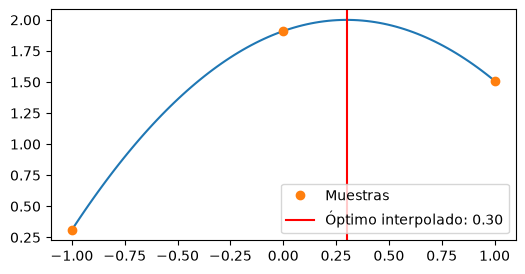

Contraste=0.01, borde=10: 1797 keypoints
Contraste=0.04, borde=10: 791 keypoints
Contraste=0.1, borde=10: 288 keypoints
Contraste=0.04, borde=5: 651 keypoints
Contraste=0.04, borde=20: 916 keypoints


In [19]:
samples_x = np.array([-1., 0., 1.])
samples_y = 2 - (samples_x - 0.3)**2
first = (samples_y[2] - samples_y[0]) / 2
second = samples_y[2] - 2*samples_y[1] + samples_y[0]
offset = -first / second
curve_x = np.linspace(-1, 1, 100)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(curve_x, 2 - (curve_x - 0.3)**2)
ax.plot(samples_x, samples_y, "o", label="Muestras")
ax.axvline(offset, color="red", label=f"Óptimo interpolado: {offset:.2f}")
ax.legend()
plt.show()

gray = img_camera.copy()
for contrast, edge in ((0.01, 10), (0.04, 10), (0.1, 10), (0.04, 5), (0.04, 20)):
    detector = cv2.SIFT_create(contrastThreshold=contrast, edgeThreshold=edge)
    print(f"Contraste={contrast}, borde={edge}: {len(detector.detect(gray, None))} keypoints")

### Extracción de características SIFT de una imagen

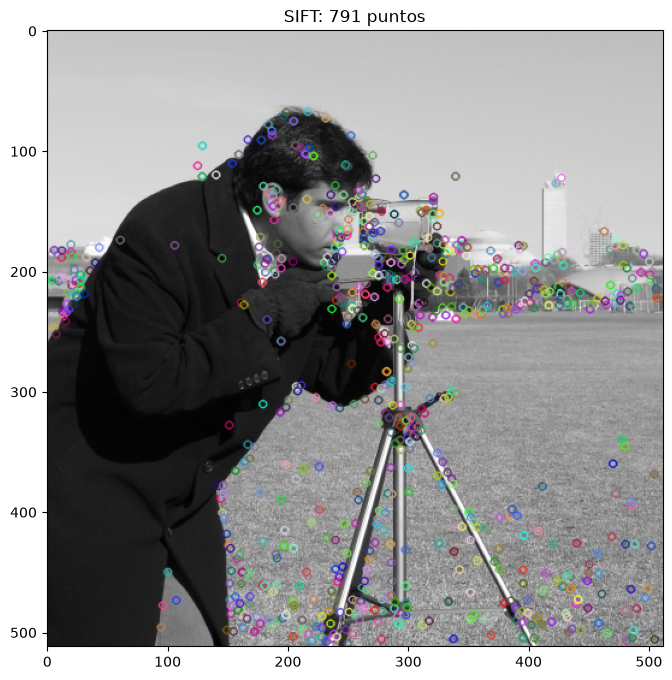

In [20]:
# Usamos la cámara de scikit-image, evitando una descarga adicional de Lenna.
sift = cv2.SIFT_create()
kps, descrs = sift.detectAndCompute(gray, None)
if descrs is None or not kps:
    raise RuntimeError("No se han detectado características SIFT")
imgout = cv2.drawKeypoints(gray, kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DEFAULT)
fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(cv2.cvtColor(imgout, cv2.COLOR_BGR2RGB))
ax.set_title(f"SIFT: {len(kps)} puntos")
plt.show()

En la imagen anterior no se aprecian ni los tamaños de los *blobs* ni las orientaciones dominantes (*orientación canónica*) de los mismos.

Podemos utilizar los campos de los *keypoints* extraidos para acceder a dicha información:

In [21]:
[attr for attr in dir(kps[0]) if not attr.startswith("__")]

['angle', 'class_id', 'convert', 'octave', 'overlap', 'pt', 'response', 'size']

### Asignación de orientación

La orientación dominante procede de un histograma de 36 bins, ponderado por la magnitud del
gradiente y una ventana gaussiana alrededor del punto, a su escala. Picos secundarios fuertes
pueden generar keypoints con igual posición y escala, pero distinta orientación.
En OpenCV, `size` es el **diámetro**, y `angle` se expresa en grados. El círculo del dibujo
representa esa escala característica, no toda la región utilizada por el descriptor.

Usamos el mismo punto en este histograma y en el descriptor siguiente: el de mayor
radio cuyo soporte completo cabe en la imagen, para ver la rejilla sin recortes.
El histograma se calcula en su nivel de la pirámide gaussiana, con suavizado circular
e interpolación del máximo, para compararlo con la orientación de OpenCV.

**Convenio de orientación:** en la imagen, X crece hacia la derecha e Y hacia abajo.
Por tanto, `atan2(Iy, Ix)` da 0° hacia la derecha, 90° hacia abajo, 180° hacia la
izquierda y 270° hacia arriba: el ángulo aumenta en sentido horario en pantalla.
La flecha indica el **gradiente**, de oscuro a claro y perpendicular al borde,
no la dirección tangente al borde. El histograma agrega gradientes ponderados de
un entorno suavizado a la escala del punto; su máximo no tiene por qué coincidir
con el borde que más destaca visualmente en la imagen original.


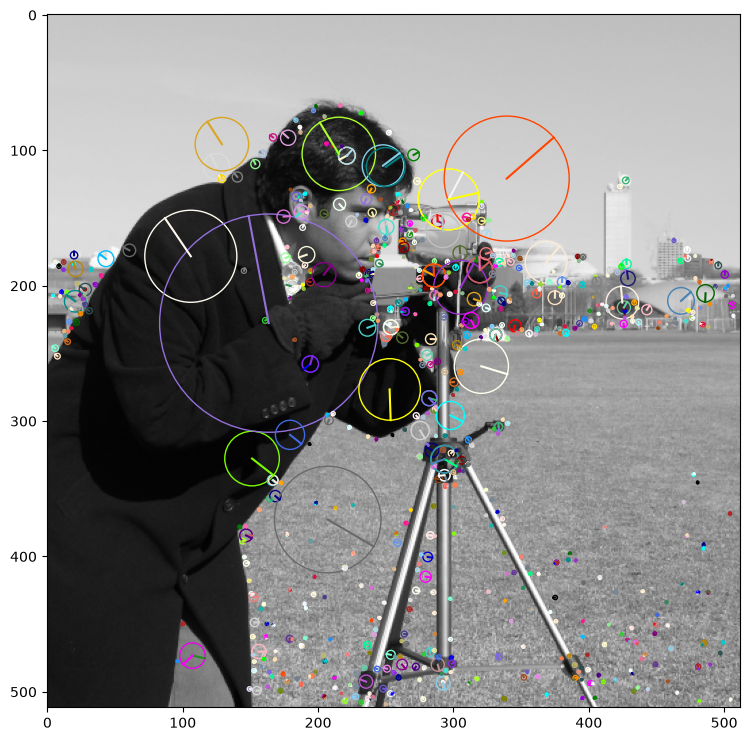

In [22]:
fig, ax = plt.subplots(1,1,figsize=(9,9))
ax.imshow(gray, cmap='gray');
colors = list(mcolors.CSS4_COLORS.keys()) # Lista de colores diferentes.
for i, kp in enumerate(kps):
  circle = plt.Circle(kp.pt, (kp.size / 2), fill=False, color=colors[i%len(colors)])
  ax.add_patch(circle)
  l = mlines.Line2D([kp.pt[0],kp.pt[0]+math.cos(math.radians(kp.angle))*(kp.size / 2)],
                    [kp.pt[1],kp.pt[1]+math.sin(math.radians(kp.angle))*(kp.size / 2)], color=colors[i%len(colors)])
  ax.add_line(l)

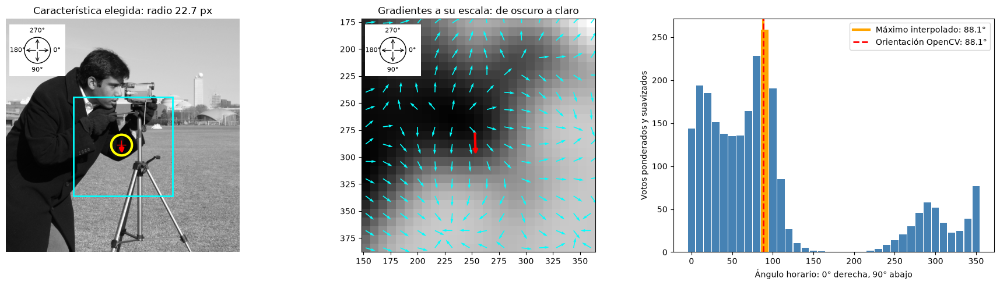

In [23]:
# Elegimos el mayor punto cuyo soporte completo del descriptor cabe en la imagen.
candidates = []
for index, point in enumerate(kps):
    angle = math.radians(point.angle)
    # Los votos interpolados alcanzan medio ancho de celda fuera de la rejilla.
    half_support = 7.5 * (point.size / 2)
    extent = half_support * (abs(np.cos(angle)) + abs(np.sin(angle)))
    x, y = point.pt
    if extent < min(x, y, gray.shape[1]-1-x, gray.shape[0]-1-y):
        candidates.append(index)
if not candidates:
    raise RuntimeError("No hay puntos con soporte completo dentro de la imagen")
example_index = max(candidates, key=lambda i: kps[i].size)
kp_orientation = kps[example_index]
sigma = kp_orientation.size / 2
cx, cy = kp_orientation.pt

# Reconstruimos solo hasta su nivel gaussiano, con los parámetros del SIFT anterior.
octave = kp_orientation.octave & 255
octave = octave if octave < 128 else octave - 256
layer = (kp_orientation.octave >> 8) & 255
levels, base_sigma = sift.getNOctaveLayers(), sift.getSigma()
gaussian_level = cv2.resize(gray.astype(np.float32), None, fx=2, fy=2, interpolation=cv2.INTER_LINEAR)
gaussian_level = cv2.GaussianBlur(gaussian_level, (0, 0), np.sqrt(base_sigma**2 - 1.0))
for current_octave in range(-1, octave + 1):
    last_layer = layer if current_octave == octave else levels
    for current_layer in range(1, last_layer + 1):
        previous_sigma = base_sigma * 2**((current_layer - 1) / levels)
        next_sigma = base_sigma * 2**(current_layer / levels)
        gaussian_level = cv2.GaussianBlur(gaussian_level, (0, 0), np.sqrt(next_sigma**2 - previous_sigma**2))
    if current_octave < octave:
        gaussian_level = cv2.resize(gaussian_level, (gaussian_level.shape[1]//2, gaussian_level.shape[0]//2),
                                    interpolation=cv2.INTER_NEAREST)

octave_scale = 2.0**octave
octave_sigma = sigma / octave_scale
px, py = np.rint(np.array([cx, cy]) / octave_scale).astype(int)
radius = int(np.rint(4.5 * octave_sigma))
y0, y1 = max(1, py-radius), min(gaussian_level.shape[0]-1, py+radius+1)
x0, x1 = max(1, px-radius), min(gaussian_level.shape[1]-1, px+radius+1)
dx = gaussian_level[y0:y1, x0+1:x1+1] - gaussian_level[y0:y1, x0-1:x1-1]
dy = gaussian_level[y0+1:y1+1, x0:x1] - gaussian_level[y0-1:y1-1, x0:x1]
patch_mag, patch_angle = cv2.cartToPolar(dx, dy, angleInDegrees=True)
yy, xx = np.mgrid[y0:y1, x0:x1]
weights = np.exp(-((xx-px)**2 + (yy-py)**2) / (2*(1.5*octave_sigma)**2))
bins = np.rint(patch_angle / 10).astype(int) % 36
orientation_hist = np.bincount(bins.ravel(), weights=(patch_mag * weights).ravel(), minlength=36)
orientation_hist = ndi.convolve1d(orientation_hist, np.array([1, 4, 6, 4, 1]) / 16, mode="wrap")
peak_bin = int(np.argmax(orientation_hist))
left, center, right = orientation_hist[(peak_bin-1) % 36], orientation_hist[peak_bin], orientation_hist[(peak_bin+1) % 36]
peak_angle = (10 * (peak_bin + 0.5*(left-right)/(left-2*center+right))) % 360

def draw_angle_compass(ax, position=(0.015, 0.745, 0.24, 0.24)):
    compass = ax.inset_axes(position)
    compass.set_facecolor("white")
    compass.add_patch(plt.Circle((0, 0), 0.65, fill=False, color="black", lw=1))
    for degree in (0, 90, 180, 270):
        angle = math.radians(degree)
        compass.annotate("", xy=(0.65*np.cos(angle), -0.65*np.sin(angle)), xytext=(0, 0),
                         arrowprops=dict(arrowstyle="->", color="black", lw=0.8))
        compass.text(0.98*np.cos(angle), -0.98*np.sin(angle), f"{degree}°",
                     ha="center", va="center", fontsize=8)
    compass.set(xlim=(-1.4, 1.4), ylim=(-1.3, 1.3), aspect="equal", xticks=[], yticks=[])
    for spine in compass.spines.values():
        spine.set_visible(False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(gray, cmap="gray")
axes[0].add_patch(plt.Rectangle(((x0-0.5)*octave_scale, (y0-0.5)*octave_scale),
                                (x1-x0)*octave_scale, (y1-y0)*octave_scale,
                                fill=False, edgecolor="cyan", linewidth=2))
axes[0].add_patch(plt.Circle((cx, cy), sigma, fill=False, color="yellow", linewidth=3))
theta = math.radians(kp_orientation.angle)
axes[0].annotate("", xy=(cx+sigma*np.cos(theta), cy+sigma*np.sin(theta)), xytext=(cx, cy),
                 arrowprops=dict(arrowstyle="->", color="red", lw=3))
axes[0].plot(cx, cy, "+", color="red", markersize=12)
axes[0].set_title(f"Característica elegida: radio {sigma:.1f} px")
axes[0].axis("off")
# Mostramos los gradientes del nivel gaussiano realmente usado, en coordenadas de imagen.
axes[1].imshow(gaussian_level[y0:y1, x0:x1], cmap="gray",
               extent=((x0-0.5)*octave_scale, (x1-0.5)*octave_scale,
                       (y1-0.5)*octave_scale, (y0-0.5)*octave_scale))
stride = 2
normalizer = np.maximum(patch_mag, 1e-6)
axes[1].quiver((xx*octave_scale)[::stride, ::stride], (yy*octave_scale)[::stride, ::stride],
               (dx/normalizer)[::stride, ::stride], (dy/normalizer)[::stride, ::stride],
               color="cyan", angles="xy", scale_units="xy", scale=1/(1.2*octave_scale), width=0.004)
axes[1].annotate("", xy=(cx+sigma*np.cos(theta), cy+sigma*np.sin(theta)), xytext=(cx, cy),
                 arrowprops=dict(arrowstyle="->", color="red", lw=3))
axes[1].set_title("Gradientes a su escala: de oscuro a claro")
axes[1].set_aspect("equal")
bar_colors = ["steelblue"] * 36
bar_colors[peak_bin] = "orange"
axes[2].bar(np.arange(36)*10, orientation_hist, width=9, color=bar_colors)
axes[2].axvline(peak_angle, color="orange", lw=3, label=f"Máximo interpolado: {peak_angle:.1f}°")
axes[2].axvline(kp_orientation.angle, color="red", linestyle="--", lw=2,
                label=f"Orientación OpenCV: {kp_orientation.angle:.1f}°")
axes[2].set_xlabel("Ángulo horario: 0° derecha, 90° abajo")
axes[2].set_ylabel("Votos ponderados y suavizados")
axes[2].legend()
draw_angle_compass(axes[0])
draw_angle_compass(axes[1])
plt.tight_layout()
plt.show()

### Descriptores SIFT

Cada keypoint, además de su localización, tamaño, y orientación característica, viene asociado con un vector característico, de dimensión 128, y cuyos valores (como se vio en la clase de teoría) están relacionados con los histogramas de gradientes locales en el entorno del blob correspondiente.

Veamos, por ejemplo, el descriptor asociado a uno de los *blobs* extraídos:

In [24]:
# Descriptor nativo de OpenCV del mismo keypoint que ilustramos.
descrs[example_index]

array([  2.,  11.,  17., 125.,  64.,   1.,   0.,   0.,  40.,  68.,  34.,
        39.,  18.,   0.,   0.,   0.,   6.,  18.,  35.,  13.,   3.,   1.,
         1.,   0.,   1.,   9.,   5.,   3.,   2.,   4.,   4.,   0.,   2.,
        31.,  39., 103., 125.,  29.,   0.,   0.,  19., 125., 125.,  46.,
        47.,  11.,   0.,   1.,  96., 110., 108.,   8.,   0.,   0.,   1.,
        22.,  17.,  21.,  11.,   7.,   2.,   7.,   5.,  15.,  10.,  46.,
        36., 110.,  76.,   7.,   0.,   0.,  60.,  26.,  21.,  70.,  87.,
         7.,   0.,  10., 125., 125.,  16.,   1.,   0.,   0.,   1.,  32.,
        20.,  47.,  16.,   1.,   2.,  14.,   6.,  11.,   1.,  12.,  46.,
        44.,  34.,  18.,   0.,   0.,   8.,  12.,  16.,  31.,  21.,   2.,
         0.,   1.,  19., 125.,  42.,   5.,   5.,   0.,   0.,   0.,   1.,
       125., 125.,   1.,   0.,   0.,   0.,   0.], dtype=float32)

### Descriptor: 4×4 celdas, 8 orientaciones por celda

Visualizamos el descriptor del mismo punto utilizado para la orientación. El vector tiene 128
componentes: no es un parche de píxeles, sino histogramas de gradientes en un marco local
escalado y orientado. SIFT reparte votos entre celdas y orientaciones próximas, pondera
espacialmente y normaliza, recorta componentes grandes y vuelve a normalizar.
La salida predeterminada de OpenCV es `float32` y tiene su propia escala numérica;
sus componentes son pesos normalizados y reescalados, no intensidades de píxel.

La rejilla orientativa muestra el marco espacial de las 16 celdas, con los mismos
índices `fila,columna` que la matriz de histogramas siguiente. Cada celda mide 3σ
en OpenCV; el círculo de radio σ indica la escala, no el tamaño del descriptor.
Los límites no son cortes duros, porque los votos
se reparten entre celdas vecinas mediante interpolación.

La rejilla tiene un lado de 12σ = 6 × `size`, no de `size`: el círculo expresa
la escala del detector, y el descriptor recoge un entorno mayor. A la derecha
mostramos también ese entorno en su marco canónico, con las filas y columnas
ordenadas como en la matriz de 4×4 histogramas. Usamos el nivel gaussiano del
keypoint; la imagen original de la izquierda sirve para localizarlo.

**De las celdas al vector:** concatenamos los ocho bins de cada celda recorriendo
la rejilla por filas: `(0,0), (0,1), (0,2), (0,3), (1,0), …, (3,3)`.
La celda `(0,0)` ocupa los índices 0–7; `(0,1)`, 8–15; `(1,0)`, 32–39;
y `(3,3)`, 120–127. No sumamos los histogramas: conservamos la información espacial
en un **vector de 128 componentes**, no en un histograma global de ocho bins.

En ambas figuras mostramos los bins en el mismo orden horario
`0°, 45°, 90°, 135°, 180°, 225°, 270°, 315°`. Así, el índice mostrado es
`j = 8 * (4 * fila + columna) + bin`. OpenCV almacena las orientaciones en el
sentido contrario: solo permutamos los valores para dibujarlos, sin modificar `desc`.
Los colores y los rangos de índices identifican la misma celda en las dos vistas.

**128 no es un límite de altura.** SIFT normaliza el vector, recorta las componentes
superiores a 0,2 y vuelve a normalizar. OpenCV reescala después a una norma próxima
a 512 y cuantiza los valores, aunque los devuelva como `float32`. Varias componentes
recortadas pueden acabar con el mismo valor máximo; este no tiene por qué ser 128
ni 0,2 en la salida final. Mostramos el máximo observado y dejamos margen por encima
de las barras, con la misma escala vertical en ambas figuras.


Radio σ=22.7 px; celda=68.2 px; rejilla=272.6 px de lado


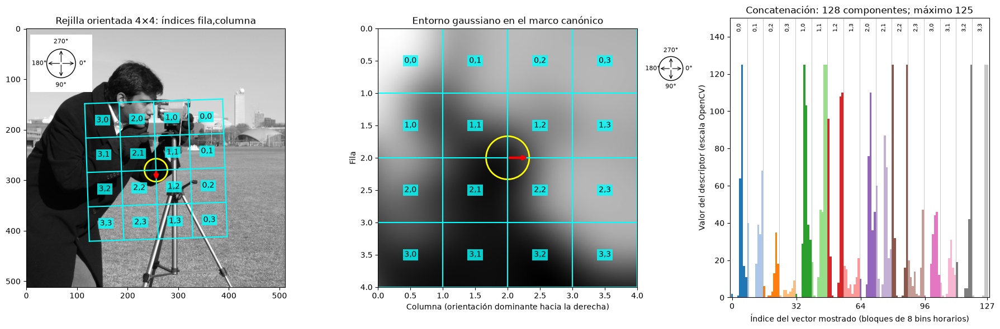

In [25]:
# Reutilizamos exactamente el keypoint y el descriptor del ejemplo de orientación.
kp, desc = kp_orientation, descrs[example_index]
sigma = kp.size / 2
theta = math.radians(kp.angle)
rotation = np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]])
# En OpenCV cada celda tiene anchura 3 sigma: lado de la rejilla = 4 * 3 sigma.
cell_width = 3 * sigma
grid_ticks = np.arange(-2, 3) * cell_width
grid_center = np.rint(np.array(kp.pt) / octave_scale) * octave_scale
# El dibujo usa el mismo centro redondeado que la rejilla y el muestreo del descriptor.
cx, cy = grid_center

fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(gray, cmap="gray")
for offset in grid_ticks:
    for segment in (np.array([[offset, grid_ticks[0]], [offset, grid_ticks[-1]]]),
                    np.array([[grid_ticks[0], offset], [grid_ticks[-1], offset]])):
        segment = segment @ rotation.T + grid_center
        axs[0].plot(segment[:, 0], segment[:, 1], color="cyan", linewidth=1.5)
for row in range(4):
    for col in range(4):
        position = (np.array([col-1.5, row-1.5]) * cell_width) @ rotation.T + grid_center
        axs[0].text(*position, f"{row},{col}", ha="center", va="center", fontsize=10,
                    color="black", bbox=dict(facecolor="cyan", alpha=0.8, edgecolor="none", pad=2))
axs[0].add_patch(plt.Circle((cx, cy), sigma, fill=False, color="yellow", linewidth=2))
axs[0].annotate("", xy=(cx+sigma*np.cos(theta), cy+sigma*np.sin(theta)), xytext=(cx, cy),
                arrowprops=dict(arrowstyle="->", color="red", lw=3))
axs[0].set_xlim(-0.5, gray.shape[1]-0.5)
axs[0].set_ylim(gray.shape[0]-0.5, -0.5)
axs[0].set_aspect("equal")
axs[0].set_title("Rejilla orientada 4×4: índices fila,columna")
# Muestreamos el mismo entorno suavizado en coordenadas canónicas de la rejilla.
canonical_axis = np.linspace(-2*cell_width, 2*cell_width, 160, endpoint=False) + cell_width/80
canonical_x, canonical_y = np.meshgrid(canonical_axis, canonical_axis)
descriptor_center = np.rint(np.array(kp.pt) / octave_scale) * octave_scale
map_x = (descriptor_center[0] + canonical_x*np.cos(theta) - canonical_y*np.sin(theta)) / octave_scale
map_y = (descriptor_center[1] + canonical_x*np.sin(theta) + canonical_y*np.cos(theta)) / octave_scale
canonical_patch = cv2.remap(gaussian_level, map_x.astype(np.float32), map_y.astype(np.float32), cv2.INTER_LINEAR)
axs[1].imshow(canonical_patch, cmap="gray", extent=(0, 4, 4, 0))
for boundary in range(5):
    axs[1].axhline(boundary, color="cyan", lw=1.5)
    axs[1].axvline(boundary, color="cyan", lw=1.5)
for row in range(4):
    for col in range(4):
        axs[1].text(col+0.5, row+0.5, f"{row},{col}", ha="center", va="center",
                    color="black", bbox=dict(facecolor="cyan", alpha=0.8, edgecolor="none", pad=2))
canonical_center = (2.0, 2.0)
axs[1].add_patch(plt.Circle(canonical_center, sigma/cell_width, fill=False, color="yellow", linewidth=2))
axs[1].annotate("", xy=(canonical_center[0]+sigma/cell_width, canonical_center[1]), xytext=canonical_center,
                arrowprops=dict(arrowstyle="->", color="red", lw=3))
axs[1].set_title("Entorno gaussiano en el marco canónico")
axs[1].set_xlabel("Columna (orientación dominante hacia la derecha)")
axs[1].set_ylabel("Fila")
print(f"Radio σ={sigma:.1f} px; celda={cell_width:.1f} px; rejilla={4*cell_width:.1f} px de lado")
histograms = desc.reshape(4, 4, 8)
display_order = (-np.arange(8)) % 8
display_histograms = histograms[:, :, display_order]
display_descriptor = display_histograms.ravel()
cell_colors = plt.cm.tab20(np.arange(16))
value_limit = max(1.0, 1.2 * float(desc.max()))
axs[2].bar(np.arange(128), display_descriptor, align="center", width=1,
           color=np.repeat(cell_colors, 8, axis=0))
for cell in range(16):
    axs[2].text(8*cell+3.5, value_limit*0.98, f"{cell//4},{cell%4}",
                ha="center", va="top", fontsize=7, rotation=90)
    if cell:
        axs[2].axvline(8*cell-0.5, color="gray", lw=0.6, alpha=0.5)
axs[2].set(xlim=(-1, 128), ylim=(0, value_limit), xticks=[0, 32, 64, 96, 127])
axs[2].set_xlabel("Índice del vector mostrado (bloques de 8 bins horarios)")
axs[2].set_ylabel("Valor del descriptor (escala OpenCV)")
axs[2].set_title(f"Concatenación: 128 componentes; máximo {desc.max():g}")
draw_angle_compass(axs[0])
draw_angle_compass(axs[1], position=(1.03, 0.745, 0.20, 0.20))
plt.tight_layout()
plt.show()

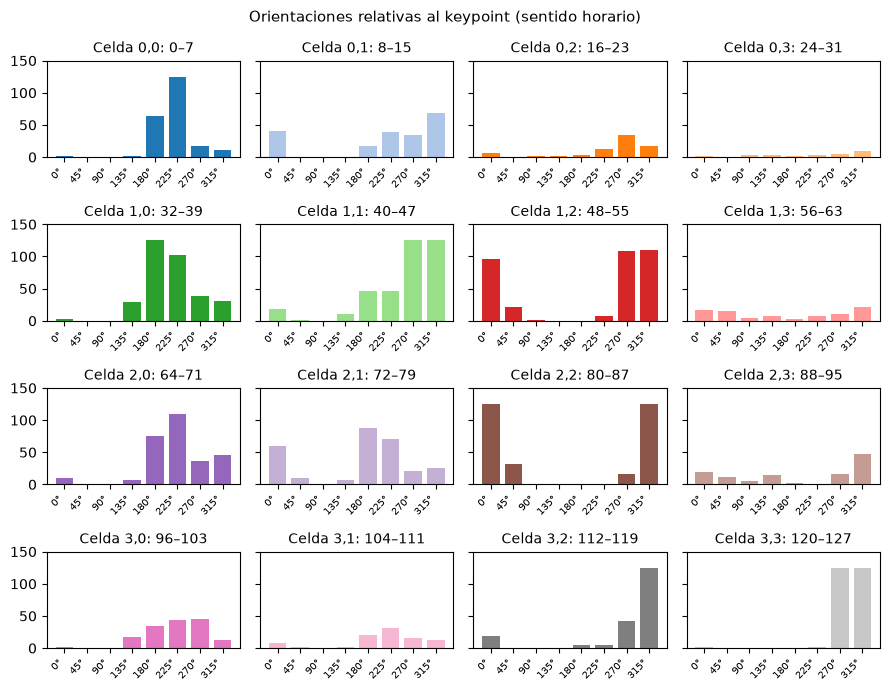

Tipo, dimensión, rango: float32 (128,) 0.0 125.0
Componentes con el máximo observado: 9
Norma OpenCV y norma unitaria: 512.5973 1.0
La concatenación mostrada contiene los mismos valores, con los bins reordenados para el dibujo.


In [26]:
# Usamos exactamente los mismos valores, orden, colores y escala que en el vector mostrado.
bin_degrees = np.arange(8) * 45
fig, axes = plt.subplots(4, 4, figsize=(9, 7), sharey=True)
fig.suptitle("Orientaciones relativas al keypoint (sentido horario)", fontsize=11)
for row in range(4):
    for col in range(4):
        axes[row, col].bar(bin_degrees, display_histograms[row, col], width=35,
                          color=cell_colors[4*row+col])
        axes[row, col].set_ylim(0, value_limit)
        axes[row, col].set_xticks(bin_degrees, [f"{degree}°" for degree in bin_degrees],
                                  rotation=45, ha="right", fontsize=7)
        start = 8 * (4*row+col)
        axes[row, col].set_title(f"Celda {row},{col}: {start}–{start+7}", fontsize=10)
fig.tight_layout()
plt.show()

# El descriptor devuelto ya ha sido recortado y normalizado por SIFT.
unit_desc = desc / np.linalg.norm(desc)
print("Tipo, dimensión, rango:", desc.dtype, desc.shape, desc.min(), desc.max())
print("Componentes con el máximo observado:", np.count_nonzero(desc == desc.max()))
print("Norma OpenCV y norma unitaria:", np.linalg.norm(desc), np.linalg.norm(unit_desc))
print("La concatenación mostrada contiene los mismos valores, con los bins reordenados para el dibujo.")


## 7. Matching: vecinos, ratio y correspondencias mutuas

Volvemos al modelo del libro y a la escena originales. Comparamos descriptores con distancia
euclídea (L2). Primero obtenemos vecinos próximos; el ratio `d1/d2 < 0.8` rechaza vecinos
ambiguos; el matching mutuo exige que ambas direcciones elijan la misma pareja.
Son filtros distintos: ninguno demuestra por sí solo que la geometría sea correcta.

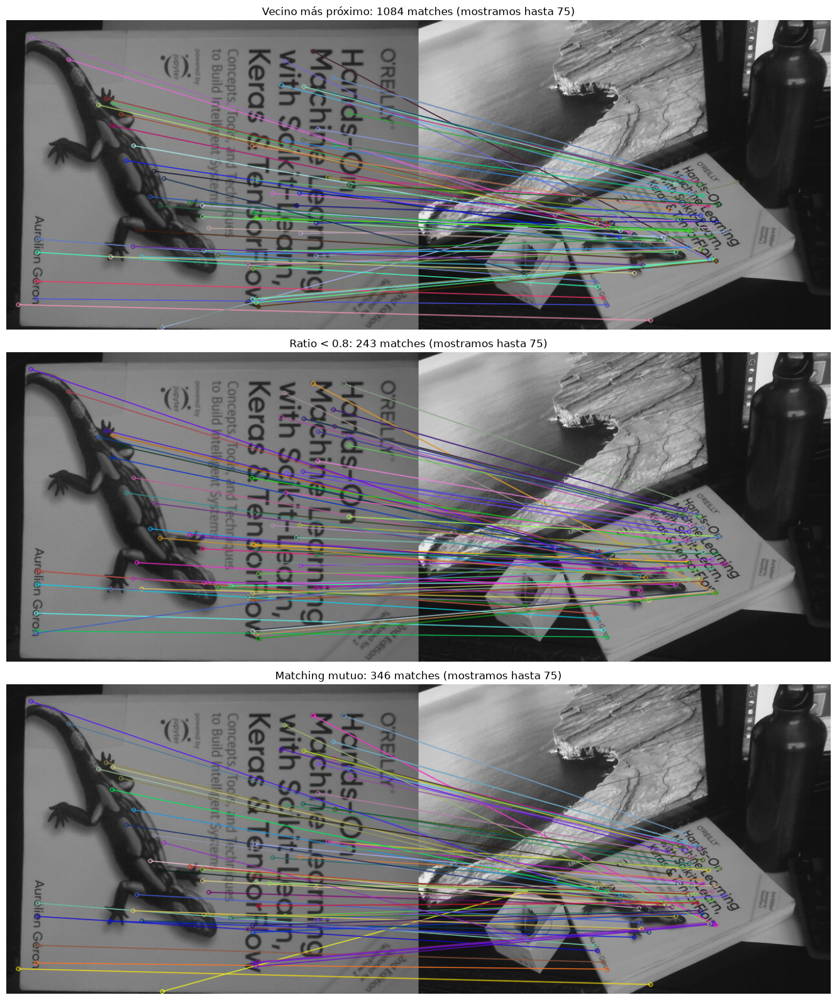

In [27]:
keypoints_1, descriptors_1 = sift.detectAndCompute(img1, None)
keypoints_2, descriptors_2 = sift.detectAndCompute(img2, None)
if descriptors_1 is None or descriptors_2 is None or min(len(descriptors_1), len(descriptors_2)) < 2:
    raise RuntimeError("Se necesitan al menos dos descriptores en cada imagen")
bf = cv2.BFMatcher(cv2.NORM_L2)
neighbors = bf.knnMatch(descriptors_1, descriptors_2, k=2)
nearest_matches = sorted([pair[0] for pair in neighbors if pair], key=lambda match: match.distance)
ratio_threshold = 0.8
ratio_matches = sorted([pair[0] for pair in neighbors
                        if len(pair) == 2 and pair[0].distance < ratio_threshold * pair[1].distance],
                       key=lambda match: match.distance)
mutual_matches = sorted(cv2.BFMatcher(cv2.NORM_L2, crossCheck=True).match(descriptors_1, descriptors_2),
                        key=lambda match: match.distance)

fig, axes = plt.subplots(3, 1, figsize=(14, 16))
for ax, selected_matches, label in zip(axes, (nearest_matches, ratio_matches, mutual_matches),
                                      ("Vecino más próximo", "Ratio < 0.8", "Matching mutuo")):
    rendered = cv2.drawMatches(img1, keypoints_1, img2, keypoints_2, selected_matches[:75], None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    ax.imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{label}: {len(selected_matches)} matches (mostramos hasta 75)")
    ax.axis("off")
plt.tight_layout()
plt.show()
matches = ratio_matches

Los campos `queryIdx` y `trainIdx` de cada _match_ contienen los índices a los keypoints originales. Por ejemplo:

In [28]:
if matches:
    match = matches[0]
    print("Distancia e índices:", match.distance, match.queryIdx, match.trainIdx)
    print("Puntos:", keypoints_1[match.queryIdx].pt, keypoints_2[match.trainIdx].pt)
else:
    print("No hay matches aceptados con este ratio")

Distancia e índices: 79.5235824584961 856 1162
Puntos: (476.229736328125, 47.76652526855469) (461.4881591796875, 373.2108459472656)


## 8. Reconocimiento planar y verificación geométrica

Los matches pueden incluir errores incluso tras el ratio. Estimamos una transformación y
pedimos que varias correspondencias apoyen la misma geometría. Una transformación afín necesita
al menos **3 pares no colineales**; una homografía, **4 pares en configuración no degenerada**.
La homografía permite representar la perspectiva de un objeto planar como la portada del libro.

Usamos RANSAC como herramienta de biblioteca: propone modelos con subconjuntos y busca
apoyo entre las correspondencias. Estudiaremos su funcionamiento al final del curso, en los
notebooks `12_RectasRANSAC_A.ipynb` y `12_RectasRANSACyHT_C.ipynb`. Aquí importa interpretar
los **inliers**, el umbral de reproyección (en píxeles de la escena) y los fallos del modelo.

Inliers afines: 92
Inliers homografía: 163 / 243
Error mediano de inliers (px): 0.5021437


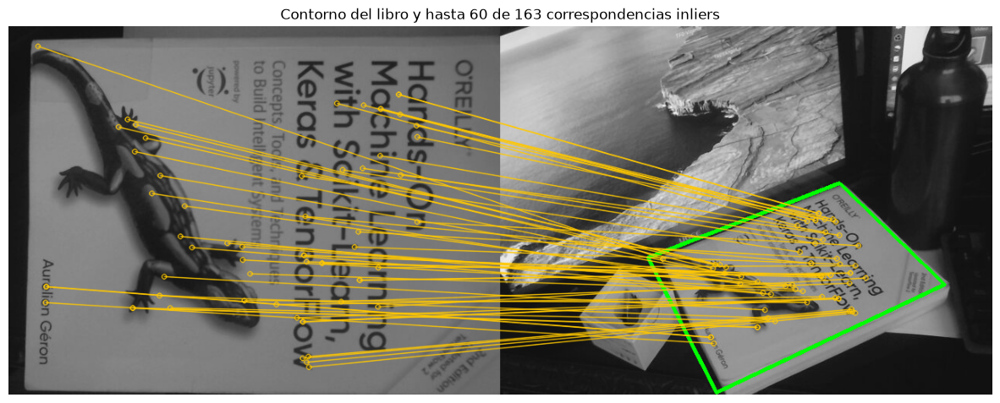

In [29]:
if len(matches) < 4:
    raise RuntimeError("No hay cuatro correspondencias para estimar una homografía")
src_points = np.float32([keypoints_1[m.queryIdx].pt for m in matches]).reshape(-1, 1, 2)
dst_points = np.float32([keypoints_2[m.trainIdx].pt for m in matches]).reshape(-1, 1, 2)
cv2.setRNGSeed(42)
affine, affine_mask = cv2.estimateAffine2D(src_points, dst_points, method=cv2.RANSAC,
                                          ransacReprojThreshold=3)
homography, inlier_mask = cv2.findHomography(src_points, dst_points, cv2.RANSAC, 3)
if homography is None or inlier_mask is None or inlier_mask.sum() < 4:
    raise RuntimeError("No se ha encontrado una homografía con apoyo suficiente")
print("Inliers afines:", int(affine_mask.sum()) if affine is not None else "sin modelo")
print("Inliers homografía:", int(inlier_mask.sum()), "/", len(matches))
projected_points = cv2.perspectiveTransform(src_points, homography)
reprojection_error = np.linalg.norm(projected_points - dst_points, axis=2).ravel()
print("Error mediano de inliers (px):", np.median(reprojection_error[inlier_mask.ravel().astype(bool)]))

height, width = img1.shape
corners = np.float32([[0, 0], [width-1, 0], [width-1, height-1], [0, height-1]]).reshape(-1, 1, 2)
projected_corners = cv2.perspectiveTransform(corners, homography)
scene_outline = cv2.cvtColor(img2, cv2.COLOR_GRAY2BGR)
cv2.polylines(scene_outline, [np.int32(np.rint(projected_corners))], True, (0, 255, 0), 3)
inlier_matches = [match for match, valid in zip(matches, inlier_mask.ravel()) if valid]
rendered = cv2.drawMatches(img1, keypoints_1, scene_outline, keypoints_2, inlier_matches[:60], None,
                           matchColor=(0, 200, 255),
                           flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
fig, ax = plt.subplots(figsize=(15, 7))
ax.imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
ax.set_title(f"Contorno del libro y hasta 60 de {len(inlier_matches)} correspondencias inliers")
ax.axis("off")
plt.show()

### Estabilidad y límites: un experimento con transformación conocida

Rotamos y cambiamos de escala el modelo, y alteramos linealmente su iluminación.
Al conocer la transformación podemos comprobar las correspondencias sin RANSAC.
La repetibilidad del detector y la corrección del matching son propiedades distintas;
el porcentaje que imprimimos mide **matches geométricamente correctos entre los aceptados**,
no una medida completa de repetibilidad. El recorte y la interpolación también influyen.

Matches aceptados: 581; correctos (<3 px): 81.2%


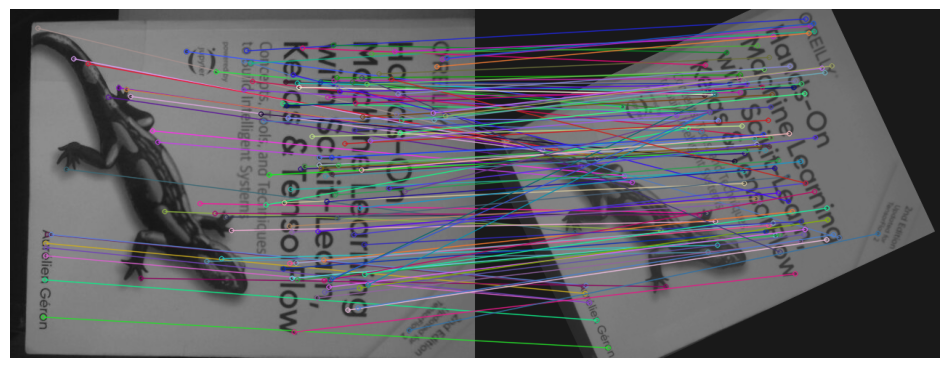

In [30]:
height, width = img1.shape
known_affine = cv2.getRotationMatrix2D(((width-1)/2, (height-1)/2), 25, 0.8)
transformed = cv2.warpAffine(img1, known_affine, (width, height))
transformed = np.clip(0.75 * transformed.astype(float) + 25, 0, 255).astype(np.uint8)
transformed_kps, transformed_desc = sift.detectAndCompute(transformed, None)
if transformed_desc is None or len(transformed_desc) < 2:
    raise RuntimeError("No hay suficientes características en la imagen transformada")
pairs = bf.knnMatch(descriptors_1, transformed_desc, k=2)
accepted = [pair[0] for pair in pairs if len(pair) == 2 and pair[0].distance < 0.8 * pair[1].distance]
if accepted:
    original_xy = np.float32([keypoints_1[m.queryIdx].pt for m in accepted])
    observed_xy = np.float32([transformed_kps[m.trainIdx].pt for m in accepted])
    expected_xy = cv2.transform(original_xy[None], known_affine)[0]
    correct = np.linalg.norm(expected_xy - observed_xy, axis=1) < 3
    print(f"Matches aceptados: {len(accepted)}; correctos (<3 px): {correct.mean():.1%}")
rendered = cv2.drawMatches(img1, keypoints_1, transformed, transformed_kps, accepted[::5], None,
                           flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
fig, ax = plt.subplots(figsize=(12, 5))
ax.imshow(cv2.cvtColor(rendered, cv2.COLOR_BGR2RGB))
ax.axis("off")
plt.show()

### Ejercicio: localizar y analizar, no solo dibujar matches

1. Cambia el ratio y el umbral de reproyección. Anota matches, inliers y error mediano;
   explica por qué más matches no implica necesariamente una detección mejor.
2. Compara el contorno obtenido con transformación afín y con homografía. ¿Qué modelo
   representa mejor la perspectiva del libro? ¿Cuándo bastaría una transformación afín?
3. Usa otra pareja modelo/escena o introduce oclusión, desenfoque y cambios de iluminación
   por separado. Documenta un caso que funcione y otro que falle.

Un contorno dibujado no demuestra que exista el objeto: inspecciona el apoyo espacial de los
inliers y la plausibilidad de la proyección. Texturas repetidas o correspondencias concentradas
en una zona pueden producir resultados engañosos.

## Referencias

* Método `cv2.findHomography` de la OpenCV: [aquí](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga4abc2ece9fab9398f2e560d53c8c9780).

* Método `cv2.estimateAffine2D` de la OpenCV: [aquí](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga27865b1d26bac9ce91efaee83e94d4dd).

* Método `cv2.estimateAffinePartial2D` de la OpenCV: [aquí](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#gad767faff73e9cbd8b9d92b955b50062d)

* Tutorial de introducción al uso de SIFT con la OpenCV: [aquí](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html).

* Tutorial de *matching* de *features* con la OpenCV: [aquí](https://docs.opencv.org/4.x/dc/dc3/tutorial_py_matcher.html).

* Tutorial de detección de objetos con la OpenCV: [aquí](https://docs.opencv.org/4.x/d1/de0/tutorial_py_feature_homography.html).


# Apéndice. HOG: de descriptores locales a una representación global

SIFT describe el entorno de cada keypoint mediante histogramas de gradientes. HOG comparte
esa idea, pero aquí recorre una **rejilla fija sobre toda la imagen** y concatena sus histogramas
en un único vector. Así obtenemos una representación global con estructura espacial, sin detectar
keypoints ni adaptar la rejilla a una orientación y escala canónicas.

1. Calculamos magnitud y orientación del gradiente.
2. Dividimos la imagen en celdas de 32×32 píxeles y acumulamos 9 orientaciones por celda.
3. Normalizamos grupos de 2×2 celdas (bloques solapados, `L2-Hys`).
4. Concatenamos todos los bloques. Para una imagen de 512×512: 16×16 celdas,
   15×15 bloques y `15×15×4×9 = 8100` componentes.

Estos son los parámetros del ejemplo, no una definición universal de HOG. La visualización
resume orientaciones por celda; el vector también incluye normalización por bloques.
HOG se ha usado para detección por ventanas y clasificación; aquí lo tratamos como descriptor global.

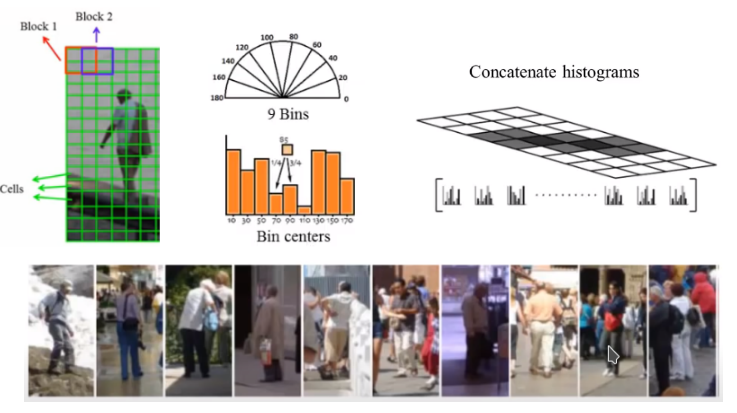

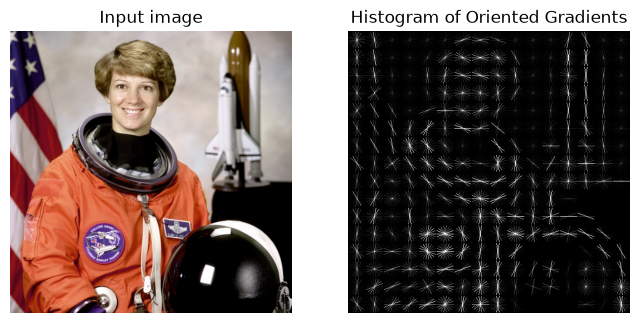

(dtype('float64'), (8100,), np.float64(0.0), np.float64(0.7218208419380614))

In [31]:
image = data.astronaut()

fd, hog_image = hog(image, orientations=9, pixels_per_cell=(32, 32), cells_per_block=(2, 2), visualize=True, channel_axis=2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)

ax1.axis('off')
ax1.imshow(image, cmap=plt.cm.gray)
ax1.set_title('Input image')

# Rescale histogram for better display
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

ax2.axis('off')
ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
ax2.set_title('Histogram of Oriented Gradients')
plt.show()
fd.dtype, fd.shape, fd.min(), fd.max()

In [32]:
nrows, ncols = np.array(image.shape[:2]) // 32
expected_length = (nrows - 1) * (ncols - 1) * 2 * 2 * 9
print("Tamaño de imagen:", image.shape[:2])
print("Componentes HOG esperadas y obtenidas:", expected_length, fd.size)

Tamaño de imagen: (512, 512)
Componentes HOG esperadas y obtenidas: 8100 8100


### De las _hand engineering features_ a las características aprendidas: el camino hacia los _embeddings_ profundos

En este ejemplo, HOG reúne la información de toda la imagen en un **descriptor global**.
Su función es análoga a la de un embedding global de DINOv2/v3: representar una imagen
mediante un vector que pueda utilizarse, por ejemplo, para clasificación o búsqueda por similitud.

Los **descriptores locales de SIFT** son más análogos a los embeddings por parches
(_tiles_) de DINOv2. La diferencia es cómo se distribuyen: SIFT describe un conjunto
disperso (_sparse_) de puntos de interés, cada uno con su escala y orientación;
DINOv2 obtiene descriptores sobre una rejilla regular de parches de tamaño fijo.

La analogía se refiere al papel de estas representaciones: HOG y SIFT se construyen
con reglas diseñadas manualmente, mientras que DINO aprende características que incorporan
el contexto de la imagen. En el siguiente notebook exploraremos sus representaciones
globales y por parches, y las similitudes que permiten capturar.

Referencia: [ejemplo HOG de scikit-image](https://scikit-image.org/docs/stable/auto_examples/features_detection/plot_hog.html).
Vídeo del material original: [explicación de HOG](https://www.youtube.com/watch?v=0Zib1YEE4LU).